# Bagian A — Linear Regression

**Dataset :** Diabetes Dataset dari `scikit-learn`  


## A1. Deskripsi Dataset

Dataset Diabetes tersedia melalui fungsi `load_diabetes()` dari `scikit-learn`. Dataset Diabetes memiliki 442 baris, 10 fitur numerik, dan satu variabel target numerik kontinu. Dataset digunakan untuk memprediksi perkembangan diabetes secara kuantitatif satu tahun setelah pengukuran awal berdasarkan karakteristik pasien.

Sepuluh fitur yang digunakan meliputi age (usia), sex (jenis kelamin), bmi (indeks massa tubuh), bp (tekanan darah), s1 (kolesterol total), s2 (LDL), s3 (HDL), s4 (rasio kolesterol total terhadap HDL), s5 (logaritma trigliserida), dan s6 (kadar gula darah).

Variabel target yang digunakan adalah target, yaitu ukuran kuantitatif perkembangan diabetes setelah satu tahun.

**Sumber:** https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme()
data = load_diabetes(as_frame=True)
df = data.frame.copy()
target_col = "target"
feature_cols = list(data.feature_names)

print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom termasuk target: {df.shape[1]}")
print(f"Jumlah fitur: {len(feature_cols)}")
print("Fitur:", feature_cols)
print("Target:", target_col)
display(df.head())

Jumlah baris: 442
Jumlah kolom termasuk target: 11
Jumlah fitur: 10
Fitur: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target: target


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## A2. Eksplorasi dan Visualisasi Data

Tampilkan statistik deskriptif. Setelah itu, tiga visualisasi dibuat: distribusi target, heatmap korelasi, dan scatter plot fitur terhadap target.

In [ ]:
display(df.describe().T)
print("Jumlah missing value per kolom:")
display(df.isna().sum().to_frame("missing_values"))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


Jumlah missing value per kolom:


,missing_values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Jumlah baris duplikat: 0


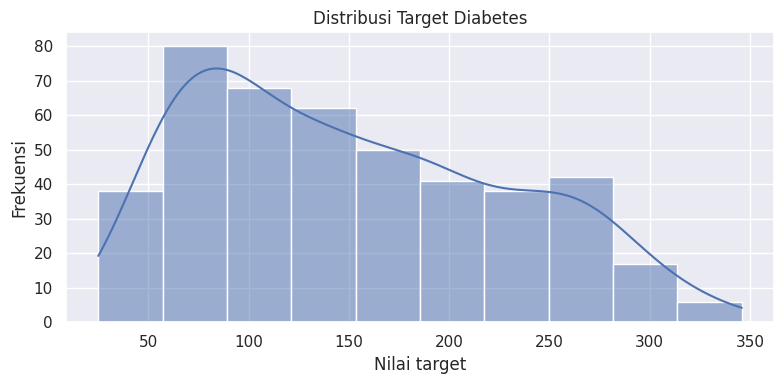

Temuan: rentang histogram, bentuk distribusi, dan target tampak simetris atau menceng.


In [ ]:
# Visualisasi 1: histogram distribusi variabel target
plt.figure(figsize=(8, 4))
sns.histplot(df[target_col], kde=True)
plt.title("Distribusi Target Diabetes")
plt.xlabel("Nilai target")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

print("Temuan: rentang histogram, bentuk distribusi, dan target tampak simetris atau menceng.")

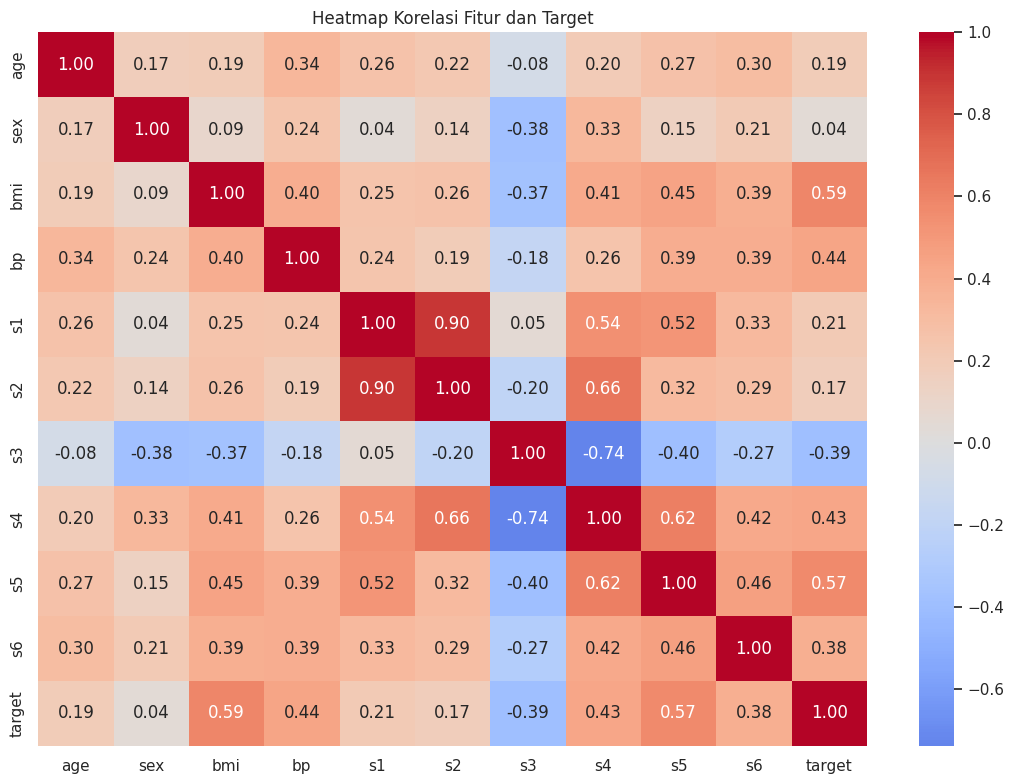

Temuan: nilai korelasi mendekati +1 menunjukkan hubungan linear positif, mendekati -1 negatif, dan mendekati 0 hubungan linear lemah.


In [ ]:
# Visualisasi 2: heatmap korelasi antarfitur
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Heatmap Korelasi Fitur dan Target")
plt.tight_layout()
plt.show()

print("Temuan: nilai korelasi mendekati +1 menunjukkan hubungan linear positif, mendekati -1 negatif, dan mendekati 0 hubungan linear lemah.")

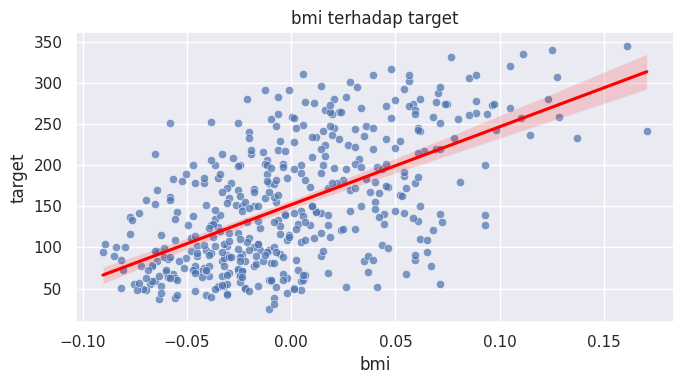

Fitur dengan korelasi absolut terbesar terhadap target pada dataset ini: bmi (korelasi = 0.586).
Temuan: titik mengikuti tren naik/turun dan seberapa besar sebarannya.


In [ ]:
# Visualisasi 3: scatter plot fitur terhadap target
corr_target = df.corr(numeric_only=True)[target_col].drop(target_col)
top_feature = corr_target.abs().sort_values(ascending=False).index[0]
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x=top_feature, y=target_col, alpha=0.7)
sns.regplot(data=df, x=top_feature, y=target_col, scatter=False, color="red")
plt.title(f"{top_feature} terhadap target")
plt.tight_layout()
plt.show()
print(f"Fitur dengan korelasi absolut terbesar terhadap target pada dataset ini: {top_feature} (korelasi = {corr_target[top_feature]:.3f}).")
print("Temuan: titik mengikuti tren naik/turun dan seberapa besar sebarannya.")

## A3. Preprocessing

Periksa kembali data duplikat dan missing value bila ditemukan. Outlier diperiksa menggunakan batas IQR. Hasil pemeriksaan dilaporkan agar keputusan tidak menghilangkan data tanpa alasan. Seluruh proses yang belajar parameter dilakukan di dalam pipeline pada data latih untuk mengurangi data leakage.

In [ ]:
# Periksa duplikat
df_clean = df.copy()
duplicate_count = int(df_clean.duplicated().sum())
if duplicate_count:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplikat yang ditemukan dan dihapus:", duplicate_count)
print("Ukuran data setelah pemeriksaan duplikat:", df_clean.shape)

# Periksa missing values
print("Total missing values:", int(df_clean.isna().sum().sum()))
print("Tidak ada encoding kategori karena seluruh fitur numerik.")

# Deteksi outlier dengan aturan IQR untuk setiap fitur
outlier_summary = []
for col in feature_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df_clean[col] < low) | (df_clean[col] > high)).sum())
    outlier_summary.append({"fitur": col, "batas_bawah": low, "batas_atas": high, "jumlah_outlier_IQR": count})
outlier_table = pd.DataFrame(outlier_summary)
display(outlier_table)
print("Keputusan: outlier tidak dihapus otomatis karena batas IQR hanya penanda awal.")

Duplikat yang ditemukan dan dihapus: 0
Ukuran data setelah pemeriksaan duplikat: (442, 11)
Total missing values: 0
Tidak ada encoding kategori karena seluruh fitur numerik.


,fitur,batas_bawah,batas_atas,jumlah_outlier_IQR
0,age,-0.150362,0.151139,0
1,sex,-0.187624,0.193663,0
2,bmi,-0.132445,0.129464,3
3,bp,-0.145106,0.144094,0
4,s1,-0.128157,0.122267,8
5,s2,-0.120663,0.120149,7
6,s3,-0.131760,0.125954,7
7,s4,-0.150197,0.145012,2
8,s5,-0.131762,0.130949,4
9,s6,-0.124823,0.119561,9


Keputusan: outlier tidak dihapus otomatis karena batas IQR hanya penanda awal.


## A4. Pemilihan Fitur

Fitur dipilih dengan `SelectKBest(score_func=f_regression)`. Pemilihan dilakukan hanya berdasarkan data latih di dalam pipeline agar data uji tidak ikut memengaruhi pemilihan fitur. Jumlah fitur terpilih ditetapkan menjadi 6 dari 10 fitur.

## A5. Pembagian Data

Data dibagi menjadi 80% data latih dan 20% data uji. `random_state=42` membuat hasil pembagian dapat direproduksi.

In [ ]:
X = df_clean[feature_cols]
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

Ukuran X_train: (353, 10)
Ukuran X_test : (89, 10)
Ukuran y_train: (353,)
Ukuran y_test : (89,)


## A6. Pemodelan Linear Regression

Pipeline menerapkan imputasi median, scaling, pemilihan 6 fitur, lalu `LinearRegression`. Koefisien model berada pada fitur yang telah distandardisasi, sehingga koefisien menunjukkan perubahan prediksi untuk kenaikan satu standar deviasi pada fitur terpilih, dengan fitur lain tetap.

In [ ]:
linear_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_regression, k=6)),
    ("regressor", LinearRegression())
])
linear_model.fit(X_train, y_train)

selector = linear_model.named_steps["selector"]
selected_features = X_train.columns[selector.get_support()].tolist()
regressor = linear_model.named_steps["regressor"]

coef_table = pd.DataFrame({
    "fitur_terpilih": selected_features,
    "koefisien": regressor.coef_
}).sort_values("koefisien", key=np.abs, ascending=False)

display(coef_table)
print("Intercept:", round(float(regressor.intercept_), 4))
print("Interpretasi: koefisien positif berarti kenaikan fitur terstandardisasi berkaitan dengan kenaikan prediksi target, koefisien negatif berkaitan dengan penurunan prediksi, dengan fitur lain tetap.")

,fitur_terpilih,koefisien
0,bmi,28.174336
4,s5,22.935522
2,s3,-15.002318
1,bp,14.140929
3,s4,-7.927697
5,s6,1.832937


Intercept: 153.7365
Interpretasi: koefisien positif berarti kenaikan fitur terstandardisasi berkaitan dengan kenaikan prediksi target, koefisien negatif berkaitan dengan penurunan prediksi, dengan fitur lain tetap.


## A7. Evaluasi

- **MAE:** rata-rata besar kesalahan absolut.
- **MSE:** rata-rata kuadrat kesalahan.
- **RMSE:** akar MSE, dalam skala target.
- **R-squared (R²):** proporsi variasi target yang dijelaskan model, dapat bernilai negatif pada data uji.

In [ ]:
def regression_metrics(model, X_part, y_part, label):
    pred = model.predict(X_part)
    return {
        "dataset": label,
        "MAE": mean_absolute_error(y_part, pred),
        "MSE": mean_squared_error(y_part, pred),
        "RMSE": np.sqrt(mean_squared_error(y_part, pred)),
        "R2": r2_score(y_part, pred)
    }

metrics_a = pd.DataFrame([
    regression_metrics(linear_model, X_train, y_train, "Latih"),
    regression_metrics(linear_model, X_test, y_test, "Uji")
])
display(metrics_a.round(4))

,dataset,MAE,MSE,RMSE,R2
0,Latih,45.1298,3028.5884,55.0326,0.5016
1,Uji,43.8996,2931.0407,54.1391,0.4468


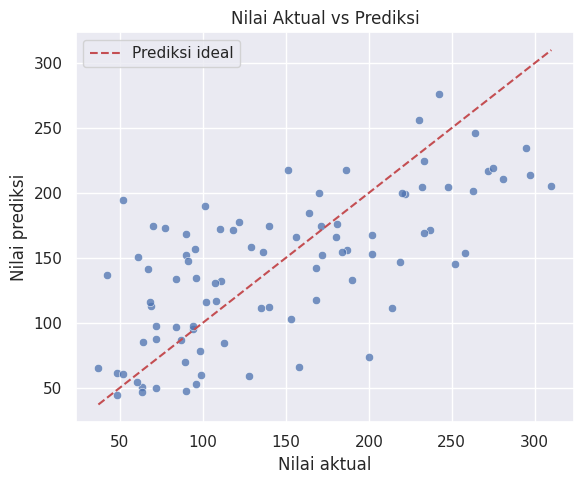

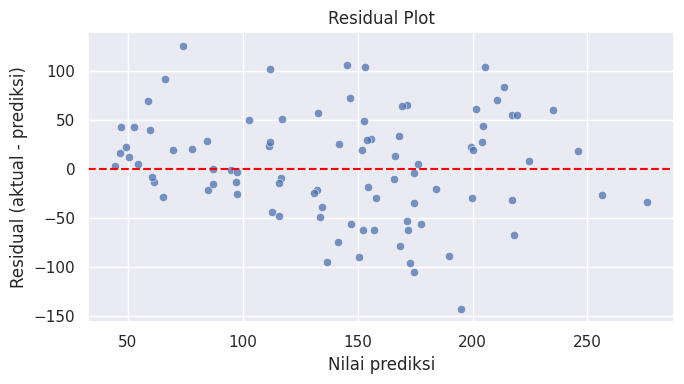

In [ ]:
y_pred = linear_model.predict(X_test)

# visualisasi nilai aktual terhadap nilai prediksi
plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.75)
low = min(float(y_test.min()), float(y_pred.min()))
high = max(float(y_test.max()), float(y_pred.max()))
plt.plot([low, high], [low, high], "r--", label="Prediksi ideal")
plt.xlabel("Nilai aktual")
plt.ylabel("Nilai prediksi")
plt.title("Nilai Aktual vs Prediksi")
plt.legend()
plt.tight_layout()
plt.show()

# Residual plot
residuals = y_test - y_pred
plt.figure(figsize=(7, 4))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.75)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Nilai prediksi")
plt.ylabel("Residual (aktual - prediksi)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

## A8. Analisis Performa

- Bandingkan MAE/RMSE data latih dan uji. Jika skor latih jauh lebih baik daripada uji, ada indikasi overfitting. Jika keduanya buruk, model mungkin underfitting atau hubungan target tidak cukup linear.
- R² yang lebih tinggi menunjukkan model menjelaskan variasi target lebih baik pada data terkait.
- Gunakan koefisien absolut terbesar untuk melihat fitur terpilih yang paling berpengaruh dalam model ini. Hubungan model tidak otomatis berarti sebab-akibat.
- Keterbatasan: dataset relatif kecil, model hanya menangkap hubungan linear, dan hasil dapat berubah jika pembagian data atau jumlah fitur berubah.

In [ ]:
train_row = metrics_a.loc[metrics_a["dataset"] == "Latih"].iloc[0]
test_row = metrics_a.loc[metrics_a["dataset"] == "Uji"].iloc[0]
print(f"Selisih RMSE (uji - latih): {test_row['RMSE'] - train_row['RMSE']:.3f}")
print(f"R2 latih: {train_row['R2']:.3f} | R2 uji: {test_row['R2']:.3f}")
print("Fitur dengan koefisien absolut terbesar:", coef_table.iloc[0]["fitur_terpilih"])

Selisih RMSE (uji - latih): -0.894
R2 latih: 0.502 | R2 uji: 0.447
Fitur dengan koefisien absolut terbesar: bmi
